# Supplementary Fig. 6b: ground truth accuracies for zero shift versus long constant shifts, by delta time

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel b of Supplementary Fig. 6: distribution over ground truth neurons of the difference between the sorting accuracy of the unit at its best constant shift of the spike timestamps and its accuracy at the longest shift (about 10 ms), for seven delta times. When the delta time is too long (30 ms), the sorted unit best matching a ground truth unit is matched by chance, the accuracy does not depend on the shift and the distribution has a single peak at 0. Source data and svg are saved in figures/8_source_data/supp_fig6b/.

**method (as in the paper's notebook supp_fig6_B_acc_vs_gt_shift_vs_dt_all_true_units.ipynb)**
* the first 50 ground truth units of the first 10 minutes of the spontaneous regime simulation and the Kilosort4 sorting
* for each delta time and each unit, the spike timestamps are shifted by constant shifts from -10 to 9.9 ms (step 0.1 ms) and the accuracy of the unit is its best agreement score with a sorted unit (`src/nodes/metrics/delta_time.py`)
* Delta_acc = (maximal accuracy over shifts) - (accuracy at the last shift, 9.9 ms)
* histogram of Delta_acc over the units (20 bins, log y-axis)

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
import spikeinterface as si
from src.nodes.metrics import delta_time

# DATA: first 10 minutes of the simulation of the spontaneous regime sorted with Kilosort4 on the Tesla V100 (the paper's run, see dataset/01_intermediate/sorting/npx_spont_v100/README.md)
GROUND_TRUTH_PATH = "dataset/00_raw/ground_truth_npx_spont_v100_10m"
SORTING_PATH = "dataset/01_intermediate/sorting/npx_spont_v100/SortingKS4_10m"

# PARAMETERS
SHIFTS_US = np.arange(-10000, 10000, 100)             # constant shifts of the ground truth spike timestamps (microseconds)
DELTA_TIMES = [0.2, 0.4, 0.6, 0.8, 1.3, 5, 30]        # ms
N_UNITS = 50                                           # first ground truth units analysed
DURATION_SEC = 600
N_JOBS = 16

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["xtick.major.width"] = 0.8 * 1.3
plt.rcParams["ytick.major.width"] = 0.8 * 1.3
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}
tight_layout_cfg = {"pad": 0.1}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Accuracy of each ground truth unit for each shift and delta time (about 5 minutes)

In [2]:
%%time

unit_ids = si.load_extractor(GROUND_TRUTH_PATH).unit_ids[:N_UNITS]
accs = delta_time.get_accuracy_vs_shift_all(GROUND_TRUTH_PATH, SORTING_PATH, unit_ids, DELTA_TIMES, SHIFTS_US, duration_sec=DURATION_SEC, n_jobs=N_JOBS)

# Delta_acc of each unit and delta time
rows = []
for dt in DELTA_TIMES:
    for u in unit_ids:
        a = accs[dt][u]
        rows.append({"delta_time_ms": dt, "unit_id": u, "max_accuracy": a.max(), "accuracy_at_longest_shift": a[-1], "delta_acc": a.max() - a[-1], "shift_at_max_us": SHIFTS_US[a.argmax()]})
df = pd.DataFrame(rows)
display(df.groupby("delta_time_ms")["delta_acc"].agg(["median", "max", lambda x: (x > 0.05).sum()]).rename(columns={"<lambda_0>": "units with delta_acc > 0.05"}).round(3))

,median,max,units with delta_acc > 0.05
delta_time_ms,,,
0.2,0.015,0.978,19
0.4,0.014,0.978,19
0.6,0.014,0.978,19
0.8,0.014,0.978,19
1.3,0.012,0.978,19
5.0,0.009,0.968,18
30.0,0.000,0.046,0


CPU times: user 1.11 s, sys: 462 ms, total: 1.57 s
Wall time: 3min 47s


## Plot, same as the paper's panel b

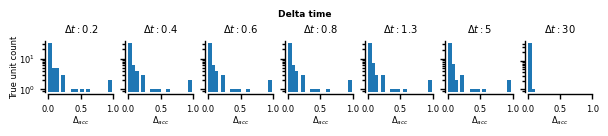

In [3]:
def plot_source_data(df: pd.DataFrame):
    """Histograms over ground truth units of the difference between their accuracy at the best shift and at the longest shift, for each delta time"""

    fig, ax = plt.subplots(1, len(DELTA_TIMES), figsize=(5.9, 1.05))
    for di, dt in enumerate(DELTA_TIMES):
        d = df[df["delta_time_ms"] == dt]["delta_acc"].values
        ax[di].hist(d, bins=20, width=0.06)
        ax[di].set_xlabel("$\\Delta_{acc}$", labelpad=0)
        if di == 0:
            ax[di].set_ylabel("True unit count", labelpad=0)
        ax[di].spines[["top", "right"]].set_visible(False)
        ax[di].set_yscale("log")
        if di != 0:
            ax[di].set_yticks([1, 10], ["", ""])
        ax[di].tick_params(which="both", width=1)
        ax[di].yaxis.set_major_locator(matplotlib.ticker.LogLocator(base=10, numticks=12))
        ax[di].yaxis.set_minor_locator(matplotlib.ticker.LogLocator(base=10.0, subs=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1), numticks=12))
        ax[di].yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax[di].spines["bottom"].set_position(("axes", -0.05))
        ax[di].yaxis.set_ticks_position("left")
        ax[di].spines["left"].set_position(("axes", -0.05))
        ax[di].set_title(f"$\\Delta t:${dt}")
        ax[di].set_xlim([0, 1])
        fig.tight_layout(**tight_layout_cfg)
    fig.suptitle("Delta time", fontsize=6.5, fontweight="bold", y=1.12)
    return fig, ax


fig, ax = plot_source_data(df)

## Save the figure and the source data

In [4]:
os.makedirs("figures/8_source_data/supp_fig6b", exist_ok=True)
fig.savefig("figures/8_source_data/supp_fig6b/supp_fig6b.svg", bbox_inches="tight", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig6b/supp_fig6b.xlsx", index=False)

## Check: replot from the saved source data

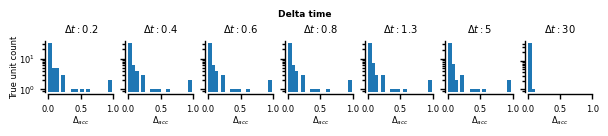

In [5]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig6b/supp_fig6b.xlsx")
fig, ax = plot_source_data(df_loaded)